In [1]:

# STEP 1: Install the tools needed for our assignment
!pip -q install ucimlrepo

print("Setup started successfully!")
print("Next, we will download the Heart Disease dataset.")


Setup started successfully!
Next, we will download the Heart Disease dataset.


In [2]:

# STEP 2: Download the dataset from the UCI repository

from ucimlrepo import fetch_ucirepo
import pandas as pd

# Fetch the Heart Disease dataset
heart_disease = fetch_ucirepo(id=45)

# Separate patient features and target labels
X = heart_disease.data.features
y = heart_disease.data.targets

# Combine them into one table
df = X.copy()
df["num"] = y.iloc[:, 0].values

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)

# Display the first five rows
display(df.head())


Dataset downloaded successfully!
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [3]:

# STEP 3: Inspect data quality

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isna().sum())

print("\nOriginal target distribution:")
print(df["num"].value_counts(dropna=False).sort_index())


Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB

Missing values in each column:
age         0
sex         0
cp 

In [4]:

# STEP 5: Clean the dataset and create a binary target

import numpy as np
import pandas as pd

# Make a separate copy of the original data
df_clean = df.copy()

# Convert the original 0-4 target into binary labels
df_clean["target"] = (df_clean["num"] > 0).astype(int)

# Remove the original target column
df_clean = df_clean.drop(columns=["num"])

# Convert missing-value markers, if any, into proper NaN values
df_clean = df_clean.replace("?", np.nan)

# Convert feature columns to numeric where possible
for col in df_clean.columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Check the result
print("Cleaned dataset shape:", df_clean.shape)
print("\nMissing values before model preprocessing:")
print(df_clean.isna().sum())

print("\nBinary target distribution:")
print(df_clean["target"].value_counts().sort_index())

display(df_clean.head())


Cleaned dataset shape: (303, 14)

Missing values before model preprocessing:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Binary target distribution:
target
0    164
1    139
Name: count, dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


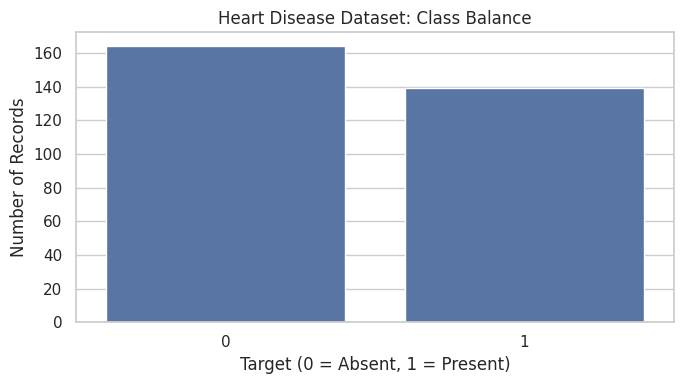

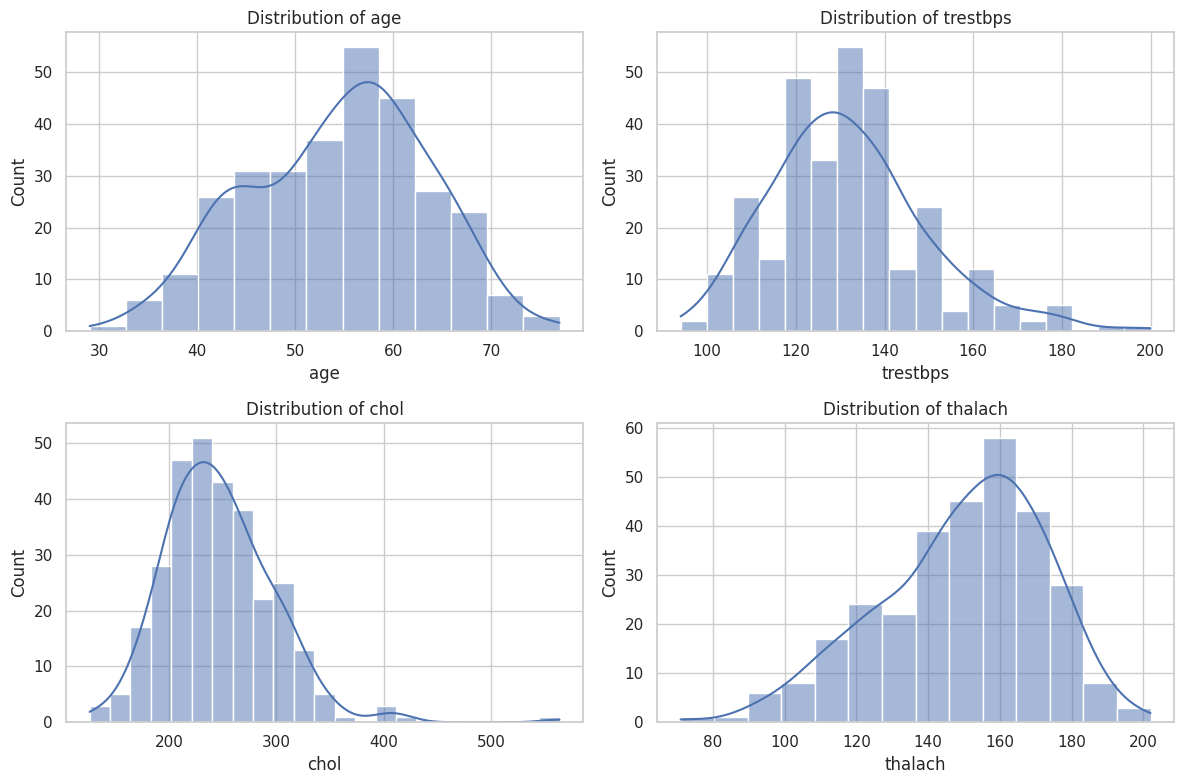

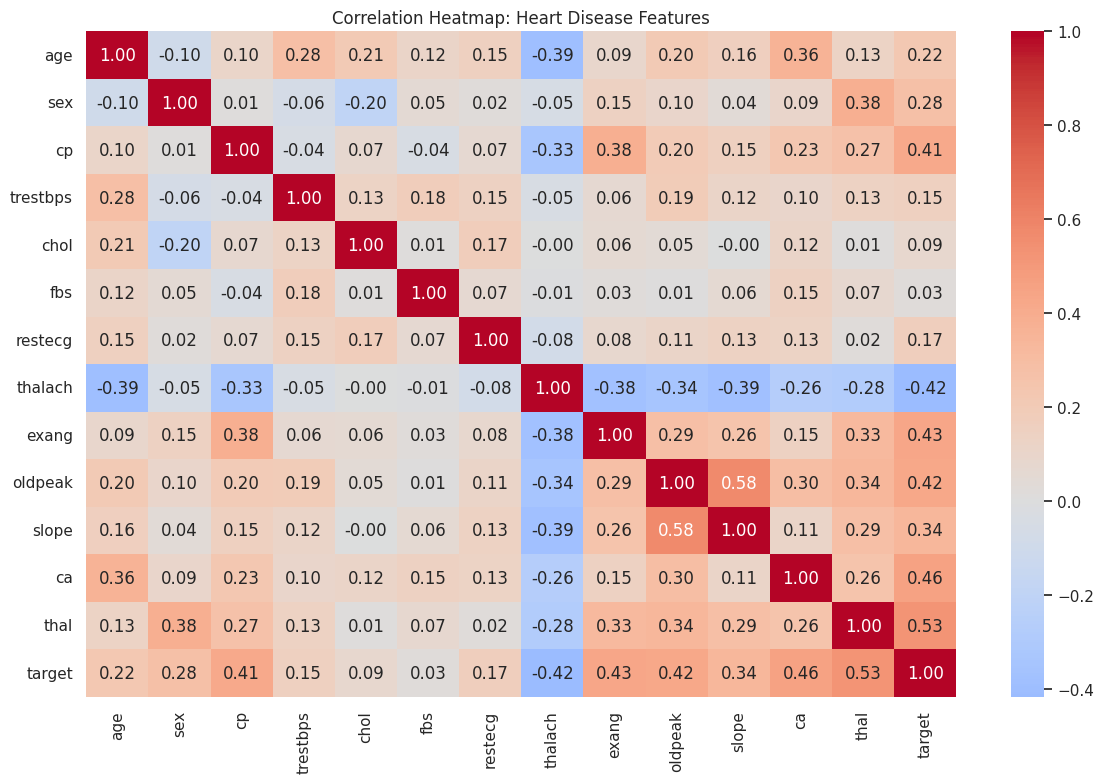

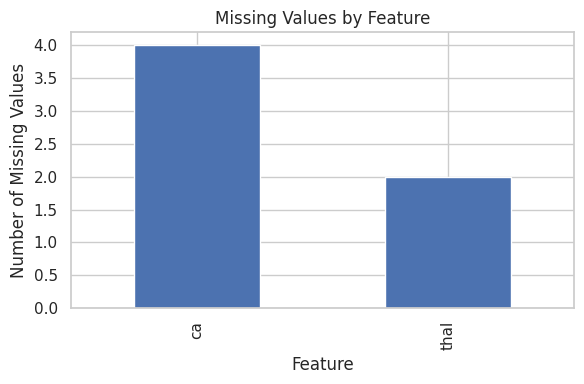

In [5]:

# STEP 6: Generate EDA visualizations

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

# Chart 1: Class balance
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, x="target")
plt.title("Heart Disease Dataset: Class Balance")
plt.xlabel("Target (0 = Absent, 1 = Present)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

# Chart 2: Distributions of important numeric features
features = ["age", "trestbps", "chol", "thalach"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, ax in zip(features, axes.flatten()):
    sns.histplot(data=df_clean, x=col, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

# Chart 3: Correlation heatmap
plt.figure(figsize=(12, 8))
corr = df_clean.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap: Heart Disease Features")
plt.tight_layout()
plt.show()

# Chart 4: Missing values
missing = df_clean.isna().sum()
missing = missing[missing > 0]

plt.figure(figsize=(6, 4))
missing.sort_values(ascending=False).plot(kind="bar")
plt.title("Missing Values by Feature")
plt.ylabel("Number of Missing Values")
plt.xlabel("Feature")
plt.tight_layout()
plt.show()


In [6]:

# STEP 7: Save EDA outputs to a folder

from pathlib import Path

output_dir = Path("/content/mlops_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(output_dir / "heart_disease_cleaned.csv", index=False)

# Save all currently open figures individually if needed.
# For the report, we will also save the main charts explicitly.
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, x="target")
plt.title("Heart Disease Dataset: Class Balance")
plt.xlabel("Target (0 = Absent, 1 = Present)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.savefig(output_dir / "class_balance.png", dpi=200)
plt.close()

print("Saved cleaned dataset and class-balance chart to:", output_dir)
print("Files:", [p.name for p in output_dir.iterdir()])


Saved cleaned dataset and class-balance chart to: /content/mlops_outputs
Files: ['class_balance.png', 'heart_disease_cleaned.csv']


In [7]:

# STEP 8: Feature engineering and model development

import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# 1. Separate input features (X) and target (y)
X = df_clean.drop(columns=["target"]).copy()
y = df_clean["target"].astype(int)

# Treat categorical-coded features as categories.
# These columns represent codes rather than continuous measurements.
categorical_features = [
    "sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"
]
numeric_features = [
    col for col in X.columns if col not in categorical_features
]

# 2. Define preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# 3. Define two classification models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=250,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42
    )
}

# 4. Evaluate using stratified 5-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "roc_auc": "roc_auc"
}

results = []
trained_pipelines = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=scoring,
        error_score="raise"
    )

    row = {"Model": name}

    for metric in scoring:
        row[metric.upper() + " (mean)"] = scores[
            "test_" + metric
        ].mean()

    results.append(row)
    trained_pipelines[name] = pipeline

results_df = pd.DataFrame(results)

print("Cross-validation results:")
display(results_df.round(3))


Cross-validation results:


,Model,ACCURACY (mean),PRECISION (mean),RECALL (mean),ROC_AUC (mean)
0,Logistic Regression,0.835,0.832,0.806,0.910
1,Random Forest,0.842,0.860,0.784,0.908


In [8]:

# STEP 10: Select the model and save the trained pipeline

from pathlib import Path
import joblib
import json

# Select based on mean cross-validation ROC-AUC
best_index = results_df["ROC_AUC (mean)"].idxmax()
best_model_name = results_df.loc[best_index, "Model"]

best_pipeline = trained_pipelines[best_model_name]
best_pipeline.fit(X, y)

# Save artifacts
artifact_dir = Path("/content/mlops_outputs/artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

model_bundle = {
    "pipeline": best_pipeline,
    "feature_columns": X.columns.tolist(),
    "model_name": best_model_name
}

joblib.dump(model_bundle, artifact_dir / "model.joblib")

summary = {
    "selected_model": best_model_name,
    "selection_metric": "mean 5-fold CV ROC-AUC",
    "results": results_df.to_dict(orient="records"),
    "n_rows": int(len(X)),
    "n_features": int(X.shape[1])
}

with open(artifact_dir / "training_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("Selected model:", best_model_name)
print("Saved model and training summary to:", artifact_dir)
print("Files:", [p.name for p in artifact_dir.iterdir()])


Selected model: Logistic Regression
Saved model and training summary to: /content/mlops_outputs/artifacts
Files: ['model.joblib', 'training_summary.json']


In [9]:

%pip -q install mlflow


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 4.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 70.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 99.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 55.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 14.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 21.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [13]:

# STEP 12: MLflow experiment tracking using SQLite

import mlflow
import mlflow.sklearn
from pathlib import Path

# Use a SQLite database for MLflow tracking
mlflow.set_tracking_uri("sqlite:////content/mlflow.db")
mlflow.set_experiment("Heart-Disease-Classification")

metric_columns = {
    "ACCURACY (mean)": "accuracy",
    "PRECISION (mean)": "precision",
    "RECALL (mean)": "recall",
    "ROC_AUC (mean)": "roc_auc"
}

for _, row in results_df.iterrows():
    model_name = row["Model"]

    with mlflow.start_run(run_name=model_name):
        mlflow.log_param("model", model_name)
        mlflow.log_param("cross_validation_folds", 5)
        mlflow.log_param("random_state", 42)
        mlflow.log_param(
            "preprocessing",
            "imputation and numeric scaling"
        )

        for source_name, metric_name in metric_columns.items():
            mlflow.log_metric(
                metric_name,
                float(row[source_name])
            )

        mlflow.set_tag(
            "selected_model",
            str(model_name == best_model_name).lower()
        )


        mlflow.sklearn.log_model(
            sk_model=trained_pipelines[model_name],
            name="model",
            serialization_format="cloudpickle"
        )

# Log the selected model's saved artifacts
with mlflow.start_run(run_name="Final-Selected-Model"):
    mlflow.log_param("selected_model", best_model_name)
    mlflow.log_param(
        "selection_metric",
        "mean cross-validation ROC-AUC"
    )

    mlflow.log_artifact(
        "/content/mlops_outputs/artifacts/training_summary.json"
    )
    mlflow.log_artifact(
        "/content/mlops_outputs/artifacts/model.joblib"
    )

print("MLflow tracking completed successfully!")
print("Tracking database: /content/mlflow.db")
print("Selected model:", best_model_name)


2026/10/20 14:56:06 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/20 14:56:13 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


MLflow tracking completed successfully!
Tracking database: /content/mlflow.db
Selected model: Logistic Regression


In [14]:

# STEP 13: Verify recorded experiment runs

mlflow.set_tracking_uri("sqlite:////content/mlflow.db")

runs = mlflow.search_runs(
    experiment_names=["Heart-Disease-Classification"],
    order_by=["start_time DESC"]
)

columns = [
    "tags.mlflow.runName",
    "params.model",
    "metrics.accuracy",
    "metrics.precision",
    "metrics.recall",
    "metrics.roc_auc"
]

display(runs[[c for c in columns if c in runs.columns]])

print("Total experiment runs:", len(runs))


,tags.mlflow.runName,params.model,metrics.accuracy,metrics.precision,metrics.recall,metrics.roc_auc
0,Final-Selected-Model,None,NaN,NaN,NaN,NaN
1,Random Forest,Random Forest,0.841585,0.860225,0.783862,0.907828
2,Logistic Regression,Logistic Regression,0.834863,0.831868,0.805556,0.909864
3,Logistic Regression,Logistic Regression,0.834863,0.831868,0.805556,0.909864


Total experiment runs: 4


In [15]:

# STEP 14: Create the prediction API

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, ConfigDict
from pathlib import Path
import pandas as pd
import joblib
import logging
import time

# Load our saved model
MODEL_PATH = Path("/content/mlops_outputs/artifacts/model.joblib")
model_bundle = joblib.load(MODEL_PATH)

pipeline = model_bundle["pipeline"]
feature_columns = model_bundle["feature_columns"]
model_name = model_bundle["model_name"]

# Create the API application
app = FastAPI(
    title="Heart Disease Prediction API",
    description="Educational ML project; not for medical diagnosis.",
    version="1.0.0"
)

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger("heart-disease-api")
request_count = 0

# Define the input fields expected by our model
class PatientFeatures(BaseModel):
    model_config = ConfigDict(extra="forbid")

    age: float
    sex: float
    cp: float
    trestbps: float
    chol: float
    fbs: float
    restecg: float
    thalach: float
    exang: float
    oldpeak: float
    slope: float
    ca: float | None = None
    thal: float | None = None

@app.get("/health")
def health():
    return {
        "status": "ok",
        "model_loaded": pipeline is not None
    }

@app.get("/metrics")
def metrics():
    return {"api_requests_total": request_count}

@app.post("/predict")
def predict(patient: PatientFeatures):
    global request_count
    start = time.perf_counter()
    request_count += 1

    try:
        # Convert input JSON into a one-row dataframe
        patient_df = pd.DataFrame([patient.model_dump()])
        patient_df = patient_df.reindex(columns=feature_columns)

        # Get the prediction and probability
        prediction = int(pipeline.predict(patient_df)[0])
        probabilities = pipeline.predict_proba(patient_df)[0]
        classes = list(pipeline.classes_)
        positive_index = classes.index(1)
        confidence = float(probabilities[positive_index])

        logger.info(
            "Prediction request completed in %.2f ms",
            (time.perf_counter() - start) * 1000
        )

        return {
            "prediction": prediction,
            "label": (
                "disease_present"
                if prediction == 1
                else "disease_absent"
            ),
            "positive_class_probability": round(confidence, 4),
            "model": model_name,
            "disclaimer": (
                "Educational model output only; "
                "not a diagnosis or clinical risk estimate."
            )
        }

    except Exception as exc:
        logger.exception("Prediction failed")
        raise HTTPException(
            status_code=422,
            detail="Input could not be processed."
        ) from exc

print("API application created!")
print("Model loaded:", model_name)
print("Features expected:", feature_columns)


API application created!
Model loaded: Logistic Regression
Features expected: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [16]:

# STEP 15: Test the API endpoints

from fastapi.testclient import TestClient

client = TestClient(app)

# Test 1: Health check
health_response = client.get("/health")
print("Health check:", health_response.status_code)
print(health_response.json())

# Test 2: Prediction
sample_patient = {
    "age": 57,
    "sex": 1,
    "cp": 2,
    "trestbps": 130,
    "chol": 236,
    "fbs": 0,
    "restecg": 0,
    "thalach": 174,
    "exang": 0,
    "oldpeak": 0.0,
    "slope": 1,
    "ca": 0,
    "thal": 2
}

prediction_response = client.post(
    "/predict",
    json=sample_patient
)

print("\nPrediction status:", prediction_response.status_code)
print("Prediction result:")
print(prediction_response.json())

# Test 3: Basic metrics
metrics_response = client.get("/metrics")
print("\nAPI metrics:", metrics_response.json())

assert health_response.status_code == 200
assert prediction_response.status_code == 200
assert "prediction" in prediction_response.json()
assert "positive_class_probability" in prediction_response.json()

print("\nAll API smoke tests passed!")


Health check: 200
{'status': 'ok', 'model_loaded': True}

Prediction status: 200
Prediction result:
{'prediction': 0, 'label': 'disease_absent', 'positive_class_probability': 0.0287, 'model': 'Logistic Regression', 'disclaimer': 'Educational model output only; not a diagnosis or clinical risk estimate.'}

API metrics: {'api_requests_total': 1}

All API smoke tests passed!


In [17]:

# STEP 16: Save the API source code

api_source = '''from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, ConfigDict
from pathlib import Path
import pandas as pd
import joblib
import logging
import time

MODEL_PATH = Path("artifacts/model.joblib")
bundle = joblib.load(MODEL_PATH)
pipeline = bundle["pipeline"]
feature_columns = bundle["feature_columns"]
model_name = bundle["model_name"]

app = FastAPI(
    title="Heart Disease Prediction API",
    description="Educational demo only; not for medical diagnosis.",
    version="1.0.0"
)

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger("heart-disease-api")
request_count = 0

class PatientFeatures(BaseModel):
    model_config = ConfigDict(extra="forbid")
    age: float
    sex: float
    cp: float
    trestbps: float
    chol: float
    fbs: float
    restecg: float
    thalach: float
    exang: float
    oldpeak: float
    slope: float
    ca: float | None = None
    thal: float | None = None

@app.middleware("http")
async def request_logging(request, call_next):
    global request_count
    started = time.perf_counter()
    response = await call_next(request)
    request_count += 1
    elapsed = (time.perf_counter() - started) * 1000
    logger.info(
        "method=%s path=%s status=%s duration_ms=%.2f",
        request.method, request.url.path, response.status_code, elapsed
    )
    response.headers["X-Process-Time-ms"] = f"{elapsed:.2f}"
    return response

@app.get("/health")
def health():
    return {"status": "ok", "model_loaded": pipeline is not None}

@app.get("/metrics")
def metrics():
    return {"api_requests_total": request_count}

@app.post("/predict")
def predict(patient: PatientFeatures):
    patient_df = pd.DataFrame([patient.model_dump()])
    patient_df = patient_df.reindex(columns=feature_columns)
    try:
        prediction = int(pipeline.predict(patient_df)[0])
        probabilities = pipeline.predict_proba(patient_df)[0]
        positive_index = list(pipeline.classes_).index(1)
        return {
            "prediction": prediction,
            "label": "disease_present" if prediction == 1 else "disease_absent",
            "positive_class_probability": round(float(probabilities[positive_index]), 4),
            "model": model_name,
            "disclaimer": "Educational model output only; not a diagnosis."
        }
    except Exception as exc:
        logger.exception("Prediction failed")
        raise HTTPException(status_code=422, detail="Input could not be processed.") from exc
'''

from pathlib import Path

api_file = Path("/content/mlops_outputs/api.py")
api_file.write_text(api_source)

print("Saved API source:", api_file)
print("File size:", api_file.stat().st_size, "bytes")


Saved API source: /content/mlops_outputs/api.py
File size: 2483 bytes


In [18]:

# STEP 17: Package the model and experiment results

from pathlib import Path
import json
import shutil
import zipfile

base = Path("/content/mlops_outputs")
base.mkdir(parents=True, exist_ok=True)

# Confirm that our key artifacts exist
required_files = [
    base / "heart_disease_cleaned.csv",
    base / "class_balance.png",
    base / "artifacts" / "model.joblib",
    base / "artifacts" / "training_summary.json",
    base / "api.py"
]

for path in required_files:
    print(("OK      " if path.exists() else "MISSING "), path)

# Save the model comparison table
results_df.to_csv(base / "model_comparison.csv", index=False)

# Save a copy of the final model and summary in the package root
shutil.copy2(
    base / "artifacts" / "model.joblib",
    base / "model.joblib"
)
shutil.copy2(
    base / "artifacts" / "training_summary.json",
    base / "training_summary.json"
)

# Create a downloadable backup
zip_path = Path("/content/mlops_colab_backup.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in base.rglob("*"):
        if path.is_file():
            z.write(path, path.relative_to(base))

print("\nBackup created:", zip_path)
print("Size in MB:", round(zip_path.stat().st_size / (1024 * 1024), 2))


OK       /content/mlops_outputs/heart_disease_cleaned.csv
OK       /content/mlops_outputs/class_balance.png
OK       /content/mlops_outputs/artifacts/model.joblib
OK       /content/mlops_outputs/artifacts/training_summary.json
OK       /content/mlops_outputs/api.py

Backup created: /content/mlops_colab_backup.zip
Size in MB: 0.05


In [19]:

from google.colab import files
files.download("/content/mlops_colab_backup.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
from pathlib import Path
import zipfile

backup_path = Path("/content/mlops_colab_backup.zip")
project_path = Path("/content/mlops-heart-disease-assignment")

if not backup_path.exists():
    print("Backup ZIP not found. Please upload mlops_colab_backup.zip to Colab first.")
else:
    project_path.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(backup_path, "r") as z:
        print("Files found in your backup:")
        for name in z.namelist():
            print("-", name)

    print("\nProject folder ready:", project_path)

Files found in your backup:
- model.joblib
- model_comparison.csv
- training_summary.json
- class_balance.png
- api.py
- heart_disease_cleaned.csv
- artifacts/model.joblib
- artifacts/training_summary.json

Project folder ready: /content/mlops-heart-disease-assignment


In [21]:
from pathlib import Path
import shutil

project = Path("/content/mlops-heart-disease-assignment")
backup = Path("/content/mlops_colab_backup.zip")

# Create the project structure
folders = [
    "src",
    "artifacts",
    "data",
    "reports",
    "tests",
    ".github/workflows"
]

for folder in folders:
    (project / folder).mkdir(parents=True, exist_ok=True)

# Extract the backup files into the project structure
import zipfile

with zipfile.ZipFile(backup, "r") as z:
    files_to_copy = {
        "api.py": "src/api.py",
        "model.joblib": "artifacts/model.joblib",
        "model_comparison.csv": "reports/model_comparison.csv",
        "training_summary.json": "reports/training_summary.json",
        "class_balance.png": "reports/class_balance.png",
        "heart_disease_cleaned.csv": "data/heart_disease_cleaned.csv"
    }

    for source, destination in files_to_copy.items():
        with z.open(source) as src, open(project / destination, "wb") as dst:
            shutil.copyfileobj(src, dst)

# Verify the files
print("Project files created:\n")

for path in sorted(project.rglob("*")):
    if path.is_file():
        print("✓", path.relative_to(project))

print("\nProject folder:", project)

Project files created:

✓ artifacts/model.joblib
✓ data/heart_disease_cleaned.csv
✓ reports/class_balance.png
✓ reports/model_comparison.csv
✓ reports/training_summary.json
✓ src/api.py

Project folder: /content/mlops-heart-disease-assignment


In [22]:
import sys
import pandas as pd
import numpy as np
import sklearn
import joblib
import mlflow
import fastapi
import pydantic

print("Python:", sys.version)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)
print("MLflow:", mlflow.__version__)
print("FastAPI:", fastapi.__version__)
print("Pydantic:", pydantic.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
pandas: 2.2.3
NumPy: 2.1.3
scikit-learn: 1.6.1
joblib: 1.6.0
MLflow: 3.17.1
FastAPI: 0.141.1
Pydantic: 2.14.1


In [23]:
from pathlib import Path

project = Path("/content/mlops-heart-disease-assignment")

requirements = """# Python environment used for the initial Colab experiments:
# Python 3.13.16
# Keep scikit-learn aligned with the saved model artifact.

pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
joblib==1.6.0
mlflow==3.17.1
fastapi==0.141.1
pydantic==2.14.1
uvicorn
ucimlrepo
matplotlib
seaborn
httpx
pytest
"""

(project / "requirements.txt").write_text(requirements)

print((project / "requirements.txt").read_text())
print("Saved to:", project / "requirements.txt")

# Python environment used for the initial Colab experiments:
# Python 3.13.16
# Keep scikit-learn aligned with the saved model artifact.

pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
joblib==1.6.0
mlflow==3.17.1
fastapi==0.141.1
pydantic==2.14.1
uvicorn
ucimlrepo
matplotlib
seaborn
httpx
pytest

Saved to: /content/mlops-heart-disease-assignment/requirements.txt


In [25]:
from pathlib import Path

project = Path("/content/mlops-heart-disease-assignment")
train_code = r'''
import json
from pathlib import Path

import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path(__file__).resolve().parents[1]
DATA_DIR = ROOT / "data"
ARTIFACT_DIR = ROOT / "artifacts"
REPORT_DIR = ROOT / "reports"

ARTIFACT_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)

def load_data():
    """Load the cleaned dataset saved during the Colab exploration."""
    df = pd.read_csv(DATA_DIR / "heart_disease_cleaned.csv")
    if "target" not in df.columns:
        raise ValueError("Dataset must contain a 'target' column.")
    X = df.drop(columns=["target"])
    y = df["target"].astype(int)
    return X, y

def build_pipeline(model):
    numeric_features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
    categorical_features = [
        "sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"
    ]

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
    ])
    preprocessing = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ])
    return Pipeline([
        ("preprocessing", preprocessing),
        ("classifier", model),
    ])

def main():
    X, y = load_data()
    models = {
        "Logistic Regression": LogisticRegression(
            max_iter=2000, class_weight="balanced", random_state=42
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=250, min_samples_leaf=2,
            class_weight="balanced", random_state=42
        ),
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scoring = {
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "roc_auc": "roc_auc",
    }

    mlflow.set_tracking_uri("sqlite:///mlflow.db")
    mlflow.set_experiment("Heart-Disease-Classification")

    results = []
    fitted_pipelines = {}

    for name, estimator in models.items():
        pipeline = build_pipeline(estimator)
        scores = cross_validate(pipeline, X, y, cv=cv, scoring=scoring)

        row = {"model": name}
        for metric in scoring:
            row[metric] = float(np.mean(scores[f"test_{metric}"]))
        results.append(row)

        with mlflow.start_run(run_name=name):
            mlflow.log_param("model_name", name)
            mlflow.log_param("cv_folds", 5)
            mlflow.log_param("random_state", 42)
            for metric in scoring:
                mlflow.log_metric(
                    metric, float(np.mean(scores[f"test_{metric}"]))
                )

        fitted_pipelines[name] = pipeline

    results_df = pd.DataFrame(results).sort_values("roc_auc", ascending=False)
    results_df.to_csv(REPORT_DIR / "model_comparison.csv", index=False)

    best_name = results_df.iloc[0]["model"]
    best_pipeline = fitted_pipelines[best_name]
    best_pipeline.fit(X, y)

    import joblib
    joblib.dump({
        "pipeline": best_pipeline,
        "feature_columns": X.columns.tolist(),
        "model_name": best_name,
    }, ARTIFACT_DIR / "model.joblib")

    summary = {
        "selected_model": best_name,
        "selection_metric": "roc_auc",
        "cross_validation": results,
        "training_rows": int(len(X)),
        "feature_count": int(X.shape[1]),
    }
    (REPORT_DIR / "training_summary.json").write_text(
        json.dumps(summary, indent=2)
    )
    print(results_df.to_string(index=False))
    print(f"\nSelected model: {best_name}")
    print("Saved model to artifacts/model.joblib")

if __name__ == "__main__":
    main()
'''

(project / "src" / "train.py").write_text(train_code.strip() + "\n")
print("Created:", project / "src" / "train.py")
print("Training script lines:", len(train_code.strip().splitlines()))

Created: /content/mlops-heart-disease-assignment/src/train.py
Training script lines: 131


In [26]:
%cd /content/mlops-heart-disease-assignment
!python src/train.py

/content/mlops-heart-disease-assignment
2026/10/20 15:26:50 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/20 15:26:50 INFO mlflow.store.db.utils: Updating database tables
2026/10/20 15:26:53 INFO mlflow.tracking.fluent: Experiment with name 'Heart-Disease-Classification' does not exist. Creating a new experiment.
              model  accuracy  precision   recall  roc_auc
Logistic Regression  0.834863   0.831868 0.805556 0.909864
      Random Forest  0.841585   0.860225 0.783862 0.907828

Selected model: Logistic Regression
Saved model to artifacts/model.joblib


In [27]:
%cd /content/mlops-heart-disease-assignment

from pathlib import Path
import joblib

model_path = Path("artifacts/model.joblib")
api_path = Path("src/api.py")

print("Model artifact exists:", model_path.exists())
print("API source exists:", api_path.exists())

bundle = joblib.load(model_path)

print("Model name:", bundle["model_name"])
print("Feature count:", len(bundle["feature_columns"]))
print("Feature columns:", bundle["feature_columns"])

/content/mlops-heart-disease-assignment
Model artifact exists: True
API source exists: True
Model name: Logistic Regression
Feature count: 13
Feature columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [28]:
from pathlib import Path

project = Path("/content/mlops-heart-disease-assignment")
api_file = project / "src" / "api.py"

print(api_file.read_text())

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, ConfigDict
from pathlib import Path
import pandas as pd
import joblib
import logging
import time

MODEL_PATH = Path("artifacts/model.joblib")
bundle = joblib.load(MODEL_PATH)
pipeline = bundle["pipeline"]
feature_columns = bundle["feature_columns"]
model_name = bundle["model_name"]

app = FastAPI(
    title="Heart Disease Prediction API",
    description="Educational demo only; not for medical diagnosis.",
    version="1.0.0"
)

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger("heart-disease-api")
request_count = 0

class PatientFeatures(BaseModel):
    model_config = ConfigDict(extra="forbid")
    age: float
    sex: float
    cp: float
    trestbps: float
    chol: float
    fbs: float
    restecg: float
    thalach: float
    exang: float
    oldpeak: float
    slope: float
    ca: float | None = None
    thal: float | None = None

@app.middleware("http")
async def request_logging(request, c

In [29]:
from pathlib import Path

project = Path("/content/mlops-heart-disease-assignment")
api_file = project / "src" / "api.py"

code = api_file.read_text()

code = code.replace(
    'MODEL_PATH = Path("artifacts/model.joblib")',
    'MODEL_PATH = Path(__file__).resolve().parents[1] / "artifacts" / "model.joblib"'
)

api_file.write_text(code)

print("Updated model path:")
for line in api_file.read_text().splitlines():
    if "MODEL_PATH" in line:
        print(line)

Updated model path:
MODEL_PATH = Path(__file__).resolve().parents[1] / "artifacts" / "model.joblib"
bundle = joblib.load(MODEL_PATH)


In [30]:
from pathlib import Path

project = Path("/content/mlops-heart-disease-assignment")

test_code = r'''
import sys
from pathlib import Path

from fastapi.testclient import TestClient

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT / "src"))

from api import app

client = TestClient(app)

def sample_patient():
    return {
        "age": 55,
        "sex": 1,
        "cp": 0,
        "trestbps": 130,
        "chol": 250,
        "fbs": 0,
        "restecg": 1,
        "thalach": 150,
        "exang": 0,
        "oldpeak": 1.0,
        "slope": 1,
        "ca": 0,
        "thal": 2
    }

def test_health_endpoint():
    response = client.get("/health")
    assert response.status_code == 200
    assert response.json()["status"] == "ok"
    assert response.json()["model_loaded"] is True

def test_prediction_endpoint():
    response = client.post("/predict", json=sample_patient())
    assert response.status_code == 200

    body = response.json()
    assert body["prediction"] in [0, 1]
    assert 0 <= body["positive_class_probability"] <= 1
    assert body["model"] == "Logistic Regression"
    assert "disclaimer" in body

def test_rejects_unexpected_input():
    patient = sample_patient()
    patient["unexpected_field"] = 123

    response = client.post("/predict", json=patient)
    assert response.status_code == 422

def test_metrics_endpoint():
    response = client.get("/metrics")
    assert response.status_code == 200
    assert "api_requests_total" in response.json()
'''

(project / "tests" / "test_api.py").write_text(test_code.strip() + "\n")

print("Created:", project / "tests" / "test_api.py")

Created: /content/mlops-heart-disease-assignment/tests/test_api.py


In [31]:
%cd /content/mlops-heart-disease-assignment
!pytest -v tests/test_api.py

/content/mlops-heart-disease-assignment
============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/mlops-heart-disease-assignment
plugins: typeguard-4.6.0, anyio-4.15.1, langsmith-0.14.11, platformdirs-4.13.4
collected 4 items                                                              

tests/test_api.py::test_health_endpoint PASSED                           [ 25%]
tests/test_api.py::test_prediction_endpoint PASSED                       [ 50%]
tests/test_api.py::test_rejects_unexpected_input PASSED                  [ 75%]
tests/test_api.py::test_metrics_endpoint PASSED                          [100%]

============================== 4 passed in 1.80s ===============================


In [32]:
from pathlib import Path

project = Path("/content/mlops-heart-disease-assignment")
workflow_dir = project / ".github" / "workflows"
workflow_dir.mkdir(parents=True, exist_ok=True)

workflow = """name: MLOps CI

on:
  push:
    branches: [main]
  pull_request:
    branches: [main]

jobs:
  test:
    runs-on: ubuntu-latest

    steps:
      - name: Check out repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.13"

      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r requirements.txt

      - name: Run API tests
        run: pytest -v tests/test_api.py
"""

workflow_file = workflow_dir / "ci.yml"
workflow_file.write_text(workflow)

print("Created:", workflow_file)
print(workflow_file.read_text())

Created: /content/mlops-heart-disease-assignment/.github/workflows/ci.yml
name: MLOps CI

on:
  push:
    branches: [main]
  pull_request:
    branches: [main]

jobs:
  test:
    runs-on: ubuntu-latest

    steps:
      - name: Check out repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.13"

      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r requirements.txt

      - name: Run API tests
        run: pytest -v tests/test_api.py



In [33]:
from pathlib import Path

project = Path("/content/mlops-heart-disease-assignment")

gitignore = """# Python
__pycache__/
*.py[cod]
*.egg-info/
.pytest_cache/
.venv/
venv/

# Secrets and environment files
.env
.env.*
!.env.example

# Local databases and MLflow artifacts
mlflow.db
mlruns/

# Notebook and editor files
.ipynb_checkpoints/
.vscode/

# Operating system files
.DS_Store
Thumbs.db
"""

(project / ".gitignore").write_text(gitignore)

print("Created:", project / ".gitignore")
print(gitignore)

Created: /content/mlops-heart-disease-assignment/.gitignore
# Python
__pycache__/
*.py[cod]
*.egg-info/
.pytest_cache/
.venv/
venv/

# Secrets and environment files
.env
.env.*
!.env.example

# Local databases and MLflow artifacts
mlflow.db
mlruns/

# Notebook and editor files
.ipynb_checkpoints/
.vscode/

# Operating system files
.DS_Store
Thumbs.db



In [34]:
from pathlib import Path

project = Path("/content/mlops-heart-disease-assignment")

dockerfile = """FROM python:3.13-slim

ENV PYTHONDONTWRITEBYTECODE=1
ENV PYTHONUNBUFFERED=1

WORKDIR /app

COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

COPY src/ ./src/
COPY artifacts/ ./artifacts/

EXPOSE 8000

CMD ["uvicorn", "src.api:app", "--host", "0.0.0.0", "--port", "8000"]
"""

(project / "Dockerfile").write_text(dockerfile)

print("Created:", project / "Dockerfile")
print(dockerfile)

Created: /content/mlops-heart-disease-assignment/Dockerfile
FROM python:3.13-slim

ENV PYTHONDONTWRITEBYTECODE=1
ENV PYTHONUNBUFFERED=1

WORKDIR /app

COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

COPY src/ ./src/
COPY artifacts/ ./artifacts/

EXPOSE 8000

CMD ["uvicorn", "src.api:app", "--host", "0.0.0.0", "--port", "8000"]



In [35]:
from pathlib import Path

project = Path("/content/mlops-heart-disease-assignment")

for name in [".gitignore", "Dockerfile"]:
    path = project / name
    print(("OK" if path.exists() else "MISSING"), name)

OK .gitignore
OK Dockerfile


In [37]:
from pathlib import Path

project = Path("/content/mlops-heart-disease-assignment")

readme = """# Heart Disease Classification — MLOps Assignment

## 1. Project Overview

This project explores the machine learning lifecycle using the UCI Heart Disease dataset. I used Google Colab to explore the data, prepare features, compare two classifiers, track experiments, save a trained model, and test a FastAPI prediction service.

## 2. Objectives

- Explore the dataset and identify missing values.
- Compare Logistic Regression and Random Forest.
- Evaluate performance using five-fold stratified cross-validation.
- Track experiments with MLflow.
- Serve predictions through FastAPI.
- Add automated tests and continuous integration.
- Prepare Docker configuration for reproducible deployment.

## 3. Dataset

The project uses the UCI Heart Disease dataset accessed through the `ucimlrepo` package.

- Records: 303
- Input features: 13
- Task: Binary classification
- Target 0: No heart disease indicated in the dataset
- Target 1: A non-zero original target value, indicating heart disease in this dataset

The original target was converted into a binary target for this experiment. Missing values in `ca` and `thal` are handled during preprocessing.

## 4. Exploratory Data Analysis

The initial analysis covered dataset dimensions, target distribution, selected feature distributions, feature correlations, and missing values. The cleaned dataset and class-balance chart are included in the project.

## 5. Model Comparison

I compared two classifiers using five-fold stratified cross-validation.

| Model | Accuracy | Precision | Recall | ROC-AUC |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.835 | 0.832 | 0.806 | 0.910 |
| Random Forest | 0.842 | 0.860 | 0.784 | 0.908 |

Logistic Regression was selected based on mean ROC-AUC. Random Forest achieved slightly higher accuracy and precision, while Logistic Regression achieved higher recall and ROC-AUC.

## 6. Experiment Tracking

MLflow records model experiments and evaluation metrics. The training script saves the model comparison, training summary, and selected model artifact.

## 7. API

The FastAPI application provides:

- `/health` — checks service and model availability.
- `/predict` — returns a binary prediction and positive-class probability.
- `/metrics` — exposes a basic API request counter.

Request logging and input validation are included.

## 8. Testing

Four API tests passed in Google Colab:

- Health endpoint
- Valid prediction
- Rejection of unexpected input
- Metrics endpoint

The GitHub Actions workflow has been created but still needs to be verified on GitHub.

## 9. Technology Stack

Python, pandas, NumPy, scikit-learn, MLflow, FastAPI, pytest, GitHub Actions, Docker, and Kubernetes configuration.

## 10. Current Status

Data exploration, model comparison, experiment tracking, model saving, and API smoke tests have been completed in Google Colab. Automated CI and container deployment remain to be verified. Cloud deployment will be marked complete only after a successful deployment and endpoint test.

## 11. Limitations and Disclaimer

This is an educational assignment using a relatively small dataset. Cross-validation results do not guarantee performance on other populations. The model is not clinically validated and must not be used for medical diagnosis or treatment decisions.
"""

(project / "README.md").write_text(readme)

print("README created:", (project / "README.md").exists())
print("README size:", (project / "README.md").stat().st_size, "bytes")

README created: True
README size: 3302 bytes


In [38]:
from pathlib import Path
import zipfile

project = Path("/content/mlops-heart-disease-assignment")

# Make src importable as a Python package
(project / "src" / "__init__.py").write_text(
    '"""Heart disease classification API and training code."""\n'
)

required = [
    "README.md",
    "requirements.txt",
    ".gitignore",
    "Dockerfile",
    "src/__init__.py",
    "src/api.py",
    "src/train.py",
    "artifacts/model.joblib",
    "data/heart_disease_cleaned.csv",
    "reports/model_comparison.csv",
    "reports/training_summary.json",
    "tests/test_api.py",
    ".github/workflows/ci.yml",
]

print("Checking project files:")
missing = []

for name in required:
    exists = (project / name).exists()
    print(("OK      " if exists else "MISSING "), name)
    if not exists:
        missing.append(name)

if missing:
    print("\nSome files are missing. Do not package yet.")
else:
    zip_path = Path("/content/mlops-heart-disease-github-upload.zip")

    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
        for path in project.rglob("*"):
            if not path.is_file():
                continue
            if any(part in {".pytest_cache", "__pycache__", ".ipynb_checkpoints"} for part in path.parts):
                continue
            archive.write(path, path.relative_to(project))

    print("\nPackage created:", zip_path)
    print("Size (MB):", round(zip_path.stat().st_size / (1024 * 1024), 2))

Checking project files:
OK       README.md
OK       requirements.txt
OK       .gitignore
OK       Dockerfile
OK       src/__init__.py
OK       src/api.py
OK       src/train.py
OK       artifacts/model.joblib
OK       data/heart_disease_cleaned.csv
OK       reports/model_comparison.csv
OK       reports/training_summary.json
OK       tests/test_api.py
OK       .github/workflows/ci.yml

Package created: /content/mlops-heart-disease-github-upload.zip
Size (MB): 0.07


In [39]:
from google.colab import files

files.download("/content/mlops-heart-disease-github-upload.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
from google.colab import files

files.download(
    "/content/mlops-heart-disease-assignment/.github/workflows/ci.yml"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:
from pathlib import Path

project = Path("/content/mlops-heart-disease-assignment")

for name in [
    "Dockerfile",
    "requirements.txt",
    "src/api.py",
    "artifacts/model.joblib",
]:
    path = project / name
    print(("✅ FOUND " if path.exists() else "❌ MISSING "), name)

✅ FOUND  Dockerfile
✅ FOUND  requirements.txt
✅ FOUND  src/api.py
✅ FOUND  artifacts/model.joblib


In [42]:
from pathlib import Path

project = Path("/content/mlops-heart-disease-assignment")
workflow_dir = project / ".github" / "workflows"
workflow_dir.mkdir(parents=True, exist_ok=True)

docker_workflow = """name: Docker Build

on:
  push:
    branches: [main]
  pull_request:
    branches: [main]

jobs:
  docker-build:
    runs-on: ubuntu-latest
    steps:
      - name: Check out repository
        uses: actions/checkout@v4

      - name: Build Docker image
        run: docker build -t heart-disease-api:ci .
"""

(workflow_dir / "docker.yml").write_text(docker_workflow)

print("Created:", workflow_dir / "docker.yml")
print(docker_workflow)

Created: /content/mlops-heart-disease-assignment/.github/workflows/docker.yml
name: Docker Build

on:
  push:
    branches: [main]
  pull_request:
    branches: [main]

jobs:
  docker-build:
    runs-on: ubuntu-latest
    steps:
      - name: Check out repository
        uses: actions/checkout@v4

      - name: Build Docker image
        run: docker build -t heart-disease-api:ci .



In [43]:
from google.colab import files
files.download(
    "/content/mlops-heart-disease-assignment/.github/workflows/docker.yml"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>